# Stage 2: EDA of shot features

This notebook looks at the features built by `scripts/02_features/02_build_features.py`
and checks how each of them relates to shot success.

- **Data:** `data/processed/shots_features.parquet`, regular seasons 2014-15 to 2024-25.
- **Season 2025-26 is removed right after loading.** It is the hold-out test set and is never
  used in EDA, so no decision about features is based on it.
- **EDA informs feature design only.** No number computed here is fed into the model;
  the model learns everything from the training data itself.

Every figure is saved as a PDF to `reports/figures/02_<name>.pdf`.

## 0. Setup

Load the data, drop the hold-out season and define a few shared things:
the data range used in every title, a percent formatter for FG% axes and a helper
that draws the court lines (in feet, hoop at (0, 0)).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Arc, Circle, Rectangle
from matplotlib.ticker import PercentFormatter

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANGE = "NBA regular seasons 2014-15 to 2024-25"
PCT = PercentFormatter(1.0, decimals=0)

df = pd.read_parquet("../data/processed/shots_features.parquet")
df = df[df["SEASON"] != "2025-26"].reset_index(drop=True)  # hold-out season, never used here
df["points"] = df["SHOT_MADE_FLAG"] * df["shot_value"]
df["x_ft"] = df["LOC_X"] / 10
df["y_ft"] = df["LOC_Y"] / 10

overall_fg = df["SHOT_MADE_FLAG"].mean()
print(f"shots: {len(df):,}")
print(f"seasons: {df['SEASON'].min()} to {df['SEASON'].max()}")
print(f"overall FG%: {overall_fg:.3f}, points per shot: {df['points'].mean():.3f}")


def draw_court(ax, color="black", lw=1):
    """Half court in feet: hoop at (0, 0), baseline at y = -5.25."""
    ax.add_patch(Circle((0, 0), 0.75, fill=False, color=color, lw=lw))           # hoop
    ax.plot([-3, 3], [-1.25, -1.25], color=color, lw=lw)                         # backboard
    ax.add_patch(Rectangle((-8, -5.25), 16, 19, fill=False, color=color, lw=lw))  # paint
    ax.add_patch(Arc((0, 13.75), 12, 12, theta1=0, theta2=180, color=color, lw=lw))  # free throw circle
    ax.add_patch(Arc((0, 0), 8, 8, theta1=0, theta2=180, color=color, lw=lw))    # restricted area
    ax.plot([-22, -22], [-5.25, 9.25], color=color, lw=lw)                       # corner 3 lines
    ax.plot([22, 22], [-5.25, 9.25], color=color, lw=lw)
    theta = np.degrees(np.arctan2(9.25, 22))
    ax.add_patch(Arc((0, 0), 47.5, 47.5, theta1=theta, theta2=180 - theta, color=color, lw=lw))  # 3PT arc
    ax.plot([-25, 25], [-5.25, -5.25], color=color, lw=lw)                       # baseline
    ax.set_xlim(-25, 25)
    ax.set_ylim(-5.25, 42)
    ax.set_aspect("equal")
    ax.set_xlabel("Court x (ft)")
    ax.set_ylabel("Distance from hoop along court (ft)")

shots: 2,305,805
seasons: 2014-15 to 2024-25
overall FG%: 0.462, points per shot: 1.053


## 1. FG% and points per shot vs distance

**What we check:** how the probability of making a shot and the expected points per shot change with
distance (1-ft bins, 0-35 ft).
**Why:** distance is expected to be the strongest feature. The points-per-shot curve shows why
the value of a shot jumps at the 3PT line (22 ft in the corner, 23.75 ft on the arc) even though FG% does not.

         all                     2PT                     3PT              
           n     fg    pts         n     fg    pts         n     fg    pts
bin                                                                       
0.0   198309  0.757  1.514  198309.0  0.757  1.514       NaN    NaN    NaN
1.0   236798  0.672  1.345  236797.0  0.672  1.345       1.0  0.000  0.000
2.0   179174  0.551  1.101  179174.0  0.551  1.101       NaN    NaN    NaN
3.0    97659  0.454  0.909   97659.0  0.454  0.909       NaN    NaN    NaN
4.0    68470  0.413  0.826   68469.0  0.413  0.826       1.0  0.000  0.000
5.0    60716  0.407  0.815   60716.0  0.407  0.815       NaN    NaN    NaN
6.0    55216  0.410  0.820   55216.0  0.410  0.820       NaN    NaN    NaN
7.0    48860  0.413  0.825   48859.0  0.413  0.825       1.0  0.000  0.000
8.0    43060  0.421  0.842   43060.0  0.421  0.842       NaN    NaN    NaN
9.0    39893  0.422  0.844   39893.0  0.422  0.844       NaN    NaN    NaN
10.0   38655  0.424  0.84

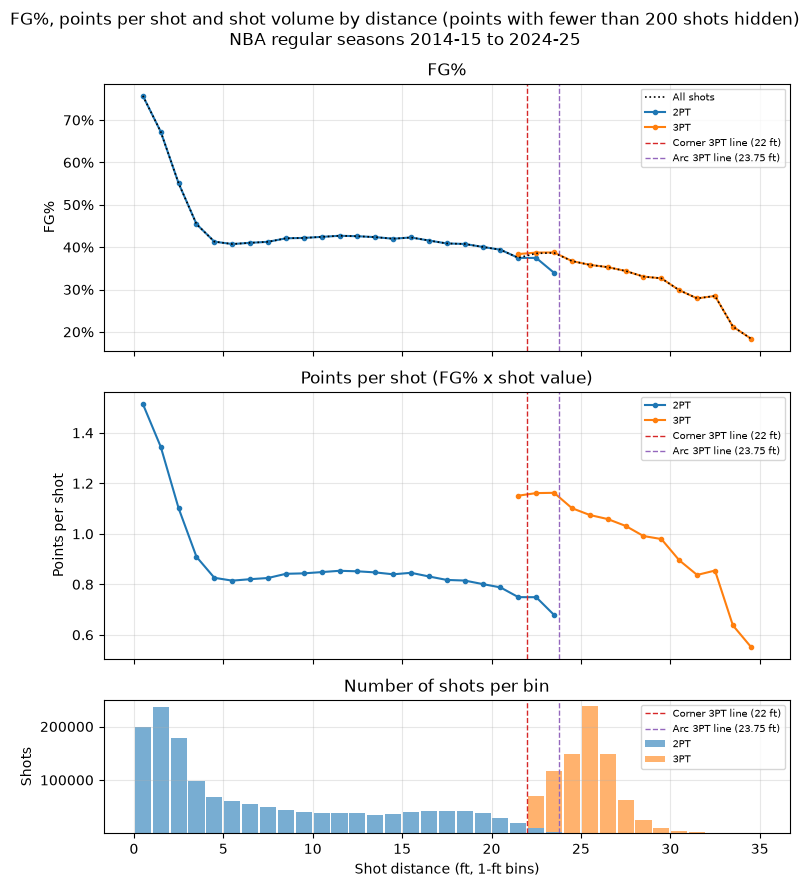

In [2]:
near = df[df["dist_ft"] < 35].copy()
near["bin"] = np.floor(near["dist_ft"])
near["type"] = np.where(near["is_three"] == 1, "3PT", "2PT")
by_type = near.groupby(["bin", "type"]).agg(n=("points", "size"), fg=("SHOT_MADE_FLAG", "mean"), pts=("points", "mean")).unstack()
by_all = near.groupby("bin").agg(n=("points", "size"), fg=("SHOT_MADE_FLAG", "mean"), pts=("points", "mean"))
print(pd.concat({"all": by_all, "2PT": by_type.xs("2PT", axis=1, level=1), "3PT": by_type.xs("3PT", axis=1, level=1)},
                axis=1).round(3).to_string())

MIN_N = 200  # hide unstable points of one shot type
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 9), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.5]})
x = by_all.index + 0.5
colors = {"2PT": "tab:blue", "3PT": "tab:orange"}
ax1.plot(x, by_all["fg"], color="black", lw=1.2, ls=":", zorder=3, label="All shots")
for t in ["2PT", "3PT"]:
    ok = by_type[("n", t)] >= MIN_N
    ax1.plot(x[ok], by_type.loc[ok, ("fg", t)], marker="o", ms=3, color=colors[t], label=t)
    ax2.plot(x[ok], by_type.loc[ok, ("pts", t)], marker="o", ms=3, color=colors[t], label=t)
ax1.yaxis.set_major_formatter(PCT)
ax1.set_ylabel("FG%")
ax1.set_title("FG%")
ax2.set_ylabel("Points per shot")
ax2.set_title("Points per shot (FG% x shot value)")
n2, n3 = by_type[("n", "2PT")].fillna(0), by_type[("n", "3PT")].fillna(0)
ax3.bar(x, n2, width=0.9, color=colors["2PT"], alpha=0.6, label="2PT")
ax3.bar(x, n3, width=0.9, bottom=n2, color=colors["3PT"], alpha=0.6, label="3PT")
ax3.set_ylabel("Shots")
ax3.set_title("Number of shots per bin")
ax3.set_xlabel("Shot distance (ft, 1-ft bins)")
for ax in (ax1, ax2, ax3):
    ax.axvline(22, color="tab:red", ls="--", lw=1, label="Corner 3PT line (22 ft)")
    ax.axvline(23.75, color="tab:purple", ls="--", lw=1, label="Arc 3PT line (23.75 ft)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")
fig.suptitle(f"FG%, points per shot and shot volume by distance (points with fewer than {MIN_N} shots hidden)\n{RANGE}")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_fg_vs_distance.pdf")
plt.show()

**Observations**

- FG% falls very fast in the first few feet: 75.7% at 0-1 ft, 55.1% at 2-3 ft, 45.4% at 3-4 ft.
- Between about 4 and 20 ft FG% is almost flat (roughly 40-43%), so the relationship is strongly non-linear;
  a single linear term in distance would not fit it.
- Just inside and just outside the 3PT line FG% is almost the same (2s at 21-22 ft: 37.5%; 3s at 22-24 ft: 38.7%),
  but points per shot are very different: the longest 2s give only about 0.68-0.75 points
  (0.749 at 21-23 ft, 0.679 at 23-24 ft), while 3s from the same range give about 1.16.
  Mid-range 2s (10-20 ft) give 0.79-0.85; only shots right at the rim (1.51 at 0-1 ft) beat a 3.
- Shot volume has two peaks: at the rim (0-2 ft) and just behind the arc (25 ft, 237,763 shots).
  Beyond 30 ft bins are small (under 5,300 shots each) and include heaves.

## 2. Shot chart: where shots are taken and how often they go in

**What we check:** the spatial distribution of shots (left) and FG% by location (right) on the half court.
**Why:** to see whether location adds information beyond distance (for example corner vs above-the-break 3s)
and to spot coordinate problems. FG% is only shown for hexagons with at least 100 shots.

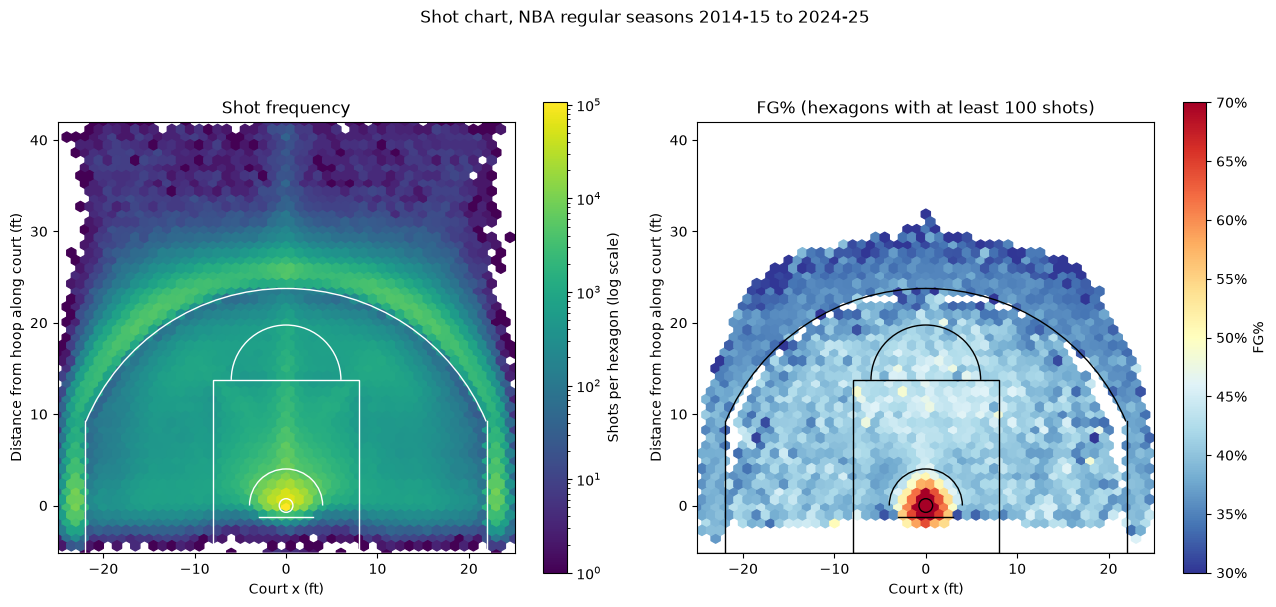

shots beyond 42 ft (not shown): 4,850


In [3]:
court = df[(df["y_ft"] <= 42)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5))
hb1 = ax1.hexbin(court["x_ft"], court["y_ft"], gridsize=50, extent=(-25, 25, -5.25, 42),
                 bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb1, ax=ax1, shrink=0.8, label="Shots per hexagon (log scale)")
ax1.set_title("Shot frequency")
hb2 = ax2.hexbin(court["x_ft"], court["y_ft"], C=court["SHOT_MADE_FLAG"], reduce_C_function=np.mean,
                 gridsize=50, extent=(-25, 25, -5.25, 42), mincnt=100, cmap="RdYlBu_r", vmin=0.3, vmax=0.7)
cb = fig.colorbar(hb2, ax=ax2, shrink=0.8, label="FG%")
cb.ax.yaxis.set_major_formatter(PCT)
ax2.set_title("FG% (hexagons with at least 100 shots)")
for ax in (ax1, ax2):
    draw_court(ax, color="white" if ax is ax1 else "black")
fig.suptitle(f"Shot chart, {RANGE}")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_shot_chart.pdf")
plt.show()

print(f"shots beyond 42 ft (not shown): {(df['y_ft'] > 42).sum():,}")

**Observations**

- Shots concentrate in three places: at the rim, in the corners and just behind the arc. The mid-range
  area between the paint and the 3PT line is much less used.
- FG% is clearly highest around the hoop and drops to the 30-40% range everywhere behind the 3PT line.
  The corner 3 hexagons are slightly better than the ones above the break (see figure 3).
- The court lines match the shot pattern well (the dense band follows the 3PT arc and corners),
  so the coordinate system and the conversion to feet look correct.
- Shots beyond 42 ft (y) are not drawn; these are almost all heaves.

## 3. 3PT FG% by angle

**What we check:** 3PT FG% as a function of the absolute shot angle (0 deg = straight on, 90 deg = along the baseline),
in 5-degree bins. Only regular 3s: no heaves and distance under 30 ft.
**Why:** corner 3s are shorter (22 ft instead of 23.75 ft). If they are also more accurate, the angle or the
`is_corner3` flag carries information that distance alone may not capture.

               n     fg  corner_share
angle_deg                            
0.0        54232  0.350         0.000
5.0        37332  0.354         0.000
10.0       37620  0.351         0.000
15.0       44882  0.350         0.000
20.0       54733  0.353         0.000
25.0       63939  0.351         0.000
30.0       68036  0.353         0.000
35.0       64395  0.353         0.000
40.0       53610  0.358         0.000
45.0       43059  0.357         0.000
50.0       31760  0.365         0.000
55.0       24959  0.364         0.000
60.0       18104  0.368         0.000
65.0       12446  0.376         0.389
70.0       17190  0.379         0.997
75.0       25686  0.380         0.998
80.0       43569  0.387         0.998
85.0       64667  0.386         0.997
90.0       42655  0.394         0.997
95.0        5539  0.392         0.997
100.0         63  0.492         0.984
corner 3 FG%: 0.387
above-the-break 3 FG%: 0.355


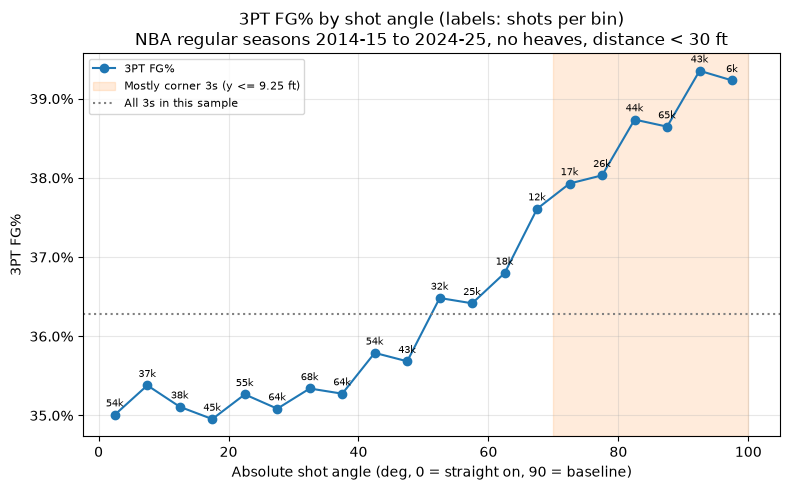

In [4]:
threes = df[(df["is_three"] == 1) & (df["is_heave"] == 0) & (df["dist_ft"] < 30)]
abs_angle = threes["angle_deg"].abs()
by_angle = threes.groupby(abs_angle // 5 * 5).agg(
    n=("SHOT_MADE_FLAG", "size"), fg=("SHOT_MADE_FLAG", "mean"), corner_share=("is_corner3", "mean")
)
print(by_angle.round(3).to_string())
print("corner 3 FG%:", round(threes.loc[threes["is_corner3"] == 1, "SHOT_MADE_FLAG"].mean(), 3))
print("above-the-break 3 FG%:", round(threes.loc[threes["is_corner3"] == 0, "SHOT_MADE_FLAG"].mean(), 3))

plot = by_angle[by_angle["n"] >= 1000]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(plot.index + 2.5, plot["fg"], marker="o", label="3PT FG%")
ax.axvspan(plot.index[plot["corner_share"] > 0.5].min(), plot.index.max() + 5,
           color="tab:orange", alpha=0.15, label="Mostly corner 3s (y <= 9.25 ft)")
ax.axhline(threes["SHOT_MADE_FLAG"].mean(), color="grey", ls=":", label="All 3s in this sample")
for a, row in plot.iterrows():
    ax.annotate(f"{row['n'] / 1000:.0f}k", (a + 2.5, row["fg"]), textcoords="offset points",
                xytext=(0, 6), ha="center", fontsize=7)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.set_xlabel("Absolute shot angle (deg, 0 = straight on, 90 = baseline)")
ax.set_ylabel("3PT FG%")
ax.set_title(f"3PT FG% by shot angle (labels: shots per bin)\n{RANGE}, no heaves, distance < 30 ft")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_three_by_angle.pdf")
plt.show()

**Observations**

- Between 0 and 50 deg 3PT FG% is flat at about 35.0-35.8%; the angle makes no difference there.
- From about 50 deg FG% rises steadily and reaches 38-39% in the corner zone (from 70 deg), with a
  maximum of 39.4% at 90-95 deg.
  Overall corner 3s go in at 38.7% vs 35.5% above the break, about 3 percentage points more.
- This gain matches the shorter distance, so part of it is already explained by `dist_ft`.
  `is_corner3` is still worth keeping as a feature and testing in the model.
- Bins with fewer than 1,000 shots (100+ deg, behind the backboard line) are not plotted.

## 4. FG% by action group

**What we check:** FG% for each `action_group` (the rule-based grouping of `ACTION_TYPE`).
**Why:** shot type describes how the shot was created (dunk, layup, step-back...). It should add a lot
of information on top of location, especially near the rim.

                      n     fg
action_group                  
jumper           901064  0.353
stepback_jumper   86988  0.404
pullup_jumper    243671  0.422
fadeaway_jumper  103451  0.431
floater          150847  0.454
hook              76279  0.484
tip_putback       78864  0.559
layup            533867  0.560
other              3194  0.666
dunk             127580  0.895


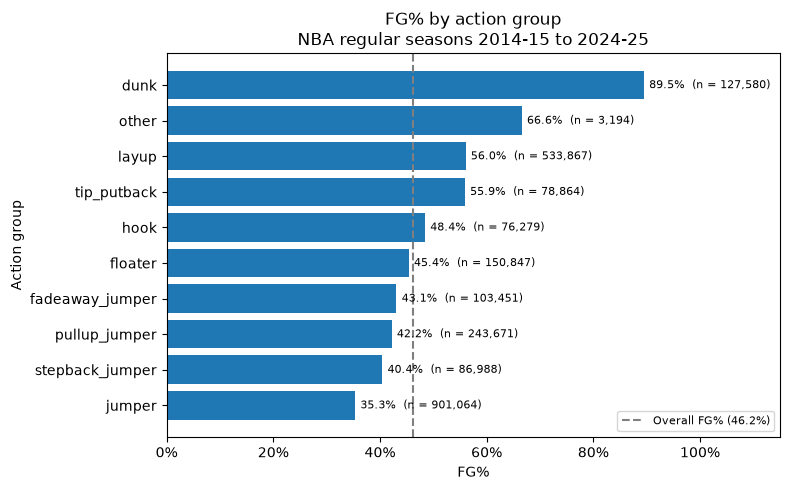

In [5]:
by_action = df.groupby("action_group", observed=True)["SHOT_MADE_FLAG"].agg(n="size", fg="mean").sort_values("fg")
print(by_action.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_action.index.astype(str), by_action["fg"], color="tab:blue")
for i, (fg, n) in enumerate(zip(by_action["fg"], by_action["n"])):
    ax.text(fg + 0.01, i, f"{fg:.1%}  (n = {n:,})", va="center", fontsize=8)
ax.axvline(overall_fg, color="grey", ls="--", label=f"Overall FG% ({overall_fg:.1%})")
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, 1.15)
ax.set_xlabel("FG%")
ax.set_ylabel("Action group")
ax.set_title(f"FG% by action group\n{RANGE}")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_fg_by_action_group.pdf")
plt.show()

**Observations**

- The groups are very different: dunks go in 89.5% of the time, layups and tip/putbacks about 56%,
  plain jump shots only 35.3%.
- Among jump shots, pull-ups (42.2%), fadeaways (43.1%) and step-backs (40.4%) are better than plain
  jumpers. This is probably because many plain jumpers are 3s, while pull-ups and fadeaways are more often
  mid-range 2s, so the model needs action group together with distance.
- `other` is small (3,194 shots) with a high FG% (66.6%). It is mostly "Driving/Running Bank shot",
  which are close shots; it is too small to matter but could be merged into `layup` or `floater` later.

## 5. End of period

**What we check:** FG% in the last 24 seconds of a period (1-s bins), separately for long shots
(30 ft or more) and the rest.
**Why:** to check that the `is_heave` threshold (30 ft or more with 3 s or less left) catches the
desperation shots, and whether short shots also get worse at the buzzer.

                             n                        fg            
long             30 ft or more Under 30 ft 30 ft or more Under 30 ft
secs_left_period                                                    
0                         7701       18670         0.056       0.296
1                         1083        9267         0.073       0.324
2                          200        6531         0.165       0.379
3                          103        4944         0.243       0.403
4                           74        3945         0.203       0.420
5                           60        3558         0.183       0.431
6                           56        3176         0.143       0.409
7                           40        2991         0.225       0.404
8                           36        2830         0.222       0.419
9                           32        2645         0.219       0.422
10                          31        2543         0.355       0.424
11                          26    

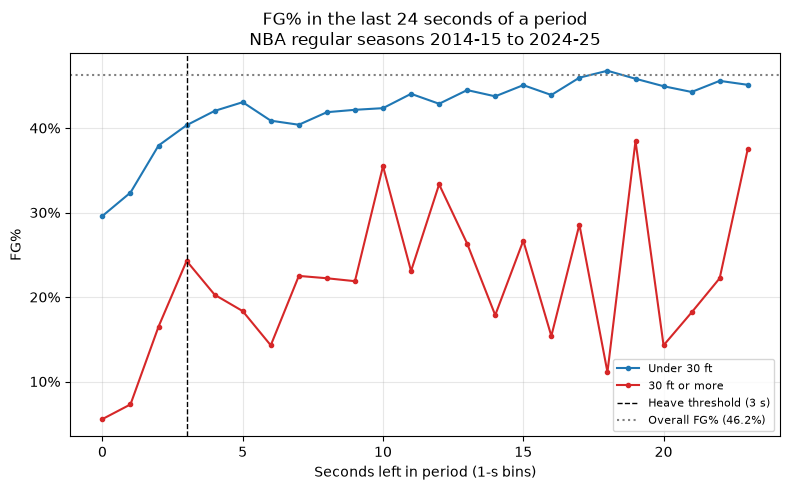

In [6]:
end = df[df["secs_left_period"] < 24].copy()
end["long"] = np.where(end["dist_ft"] >= 30, "30 ft or more", "Under 30 ft")
by_sec = end.groupby(["secs_left_period", "long"])["SHOT_MADE_FLAG"].agg(n="size", fg="mean").unstack()
print(by_sec.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for label, color in [("Under 30 ft", "tab:blue"), ("30 ft or more", "tab:red")]:
    ax.plot(by_sec.index, by_sec[("fg", label)], marker="o", ms=3, color=color, label=label)
ax.axvline(3, color="black", ls="--", lw=1, label="Heave threshold (3 s)")
ax.axhline(overall_fg, color="grey", ls=":", label=f"Overall FG% ({overall_fg:.1%})")
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Seconds left in period (1-s bins)")
ax.set_ylabel("FG%")
ax.set_title(f"FG% in the last 24 seconds of a period\n{RANGE}")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_end_of_period.pdf")
plt.show()

**Observations**

- Long shots in the final second (0 s left) go in only 5.6% of the time (7,701 shots), 7.3% with 1 s left.
  With 4 s or more the long-shot line is noisy (often under 100 shots per bin) and mostly 15-35%.
- Short shots also get worse at the buzzer: 29.6% at 0 s and 32.4% at 1 s, compared with about 42-46%
  earlier in the last 24 s. They are hurried shots even when they are not long.
- So `is_heave` captures the main effect, but `secs_left_period` itself (for example a flag for 1 s or less)
  is useful too, because the end-of-period drop is not limited to shots of 30 ft or more.

## 6. League trend by season

**What we check:** the share of 3PT attempts and FG% on 2s and 3s for each season.
**Why:** if the game changes over time, a model trained on old seasons may be biased on new ones.
This decides whether season (or time) is needed as a feature and supports using the latest season as the test set.

         share_3   fg_2   fg_3
SEASON                        
2014-15    0.268  0.485  0.350
2015-16    0.284  0.491  0.354
2016-17    0.316  0.503  0.357
2017-18    0.337  0.510  0.362
2018-19    0.359  0.520  0.355
2019-20    0.384  0.524  0.358
2020-21    0.392  0.530  0.367
2021-22    0.399  0.533  0.354
2022-23    0.387  0.548  0.361
2023-24    0.395  0.545  0.366
2024-25    0.421  0.545  0.360


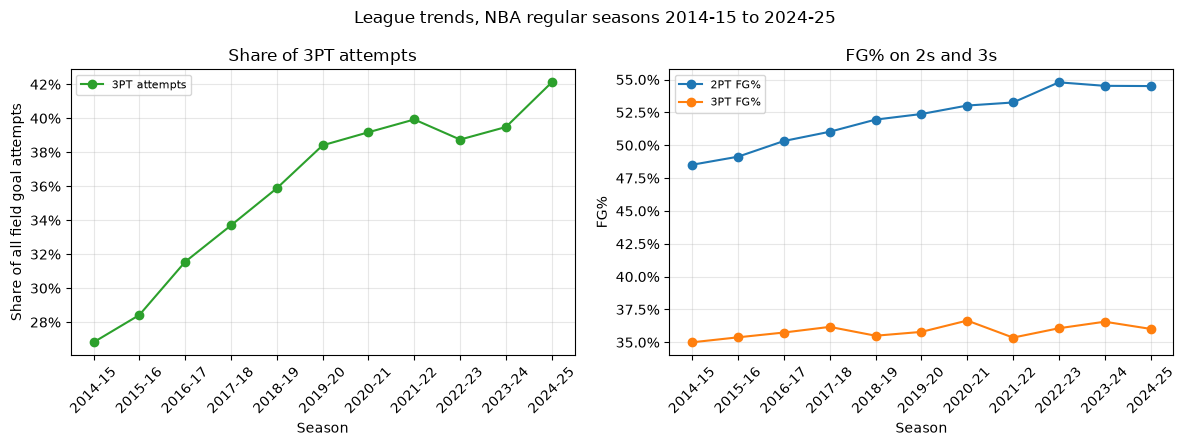

In [7]:
by_season = df.groupby("SEASON").agg(share_3=("is_three", "mean"))
by_season["fg_2"] = df[df["is_three"] == 0].groupby("SEASON")["SHOT_MADE_FLAG"].mean()
by_season["fg_3"] = df[df["is_three"] == 1].groupby("SEASON")["SHOT_MADE_FLAG"].mean()
print(by_season.round(3).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(by_season.index, by_season["share_3"], marker="o", color="tab:green", label="3PT attempts")
ax1.yaxis.set_major_formatter(PCT)
ax1.set_ylabel("Share of all field goal attempts")
ax1.set_title("Share of 3PT attempts")
ax2.plot(by_season.index, by_season["fg_2"], marker="o", label="2PT FG%")
ax2.plot(by_season.index, by_season["fg_3"], marker="o", label="3PT FG%")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax2.set_ylabel("FG%")
ax2.set_title("FG% on 2s and 3s")
for ax in (ax1, ax2):
    ax.set_xlabel("Season")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle(f"League trends, {RANGE}")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_league_trend.pdf")
plt.show()

**Observations**

- The share of 3PT attempts grew from 26.8% in 2014-15 to 42.1% in 2024-25.
- 2PT FG% rose steadily from 48.5% to 54.5-54.8% (2022-23 to 2024-25). The likely reason is that
  teams replaced long 2s with shots at the rim, so the average 2 is now a closer, easier shot.
- 3PT FG% is stable at 35-37% across all seasons.
- The rise in 2PT FG% is mostly a change in the shot mix, which location features already describe.
  Whether a season or time feature is still needed should be tested in the model with a time-based
  split (train on older seasons, validate on later ones).

## Summary for feature design

- `dist_ft` is the main feature and its effect is strongly non-linear (steep drop in the first 4 ft, then flat).
- `is_corner3` / `angle_deg`: corner 3s are about 3 percentage points better than above-the-break 3s.
- `action_group` separates shots very well (from 35% to 90% FG%) and should be used together with distance.
- `is_heave` isolates desperation shots (about 6% FG%), and the last 1-2 s also hurt short shots.
- League trends change the shot mix over time, which supports a time-based validation split.